# TechValue AI — Intelligent Computer Price Prediction
### Assignment 3: Applying, Evaluating and Comparing Multiple ML Algorithms on a Large Real-World Dataset

| | |
|---|---|
| **Student** | **M. AHMED WAQAR** |
| **Roll No.** | **FA24-BSE-070** |
| **Course** | Machine Learning Fundamentals (AIC354) — COMSATS University Islamabad, Lahore Campus |
| **Instructor** | Dr. Rao Muhammad Adeel Nawab |
| **🔗 Live deployment link** | **https://YOUR-APP-NAME.streamlit.app** *(placeholder — replace with the real Streamlit Community Cloud URL after deploying; see Section K)* |
| **Dataset** | Computer Prices 2025 (Kaggle) — 100,000 labelled computers |
| **Method** | 10-Fold Cross-Validation on the **full** dataset, 5 regression algorithms, RMSE as the main metric |

## How to run this notebook on Google Colab

1. Open <https://colab.research.google.com>, choose **File → Upload notebook**, and select this `.ipynb`.
2. Click **Runtime → Run all**.
3. When **Section B.2** runs, click **Choose Files** and upload **`computer_prices_all.csv`** (the labelled Kaggle file with the `price` column). Optionally also upload `computer_prices_test.csv` and `sample_submission.csv` — they are only needed for the optional Kaggle submission file in Section K.
4. No GPU is needed. The 10-fold comparison takes roughly 10–20 minutes on a free Colab CPU runtime.

> Colab deletes uploaded files when the runtime resets. If you get *"file not found"*, run Section B.2 again.
>
> **Kaggle API alternative:** if you have configured your own Kaggle credentials (`KAGGLE_USERNAME` / `KAGGLE_KEY` environment variables or `~/.kaggle/kaggle.json`), Section B.2 can download the competition files automatically. No credentials are stored in this notebook.

# A. Introduction

**Project objective.** Build and compare machine-learning regression models that predict the **price of a laptop or desktop computer from its hardware specifications**, then deploy the best model inside a web application (**TechValue AI**, built with Streamlit).

**Real-world problem.** Computer prices depend on many interacting specifications — processor, graphics card, memory, storage, screen, brand, and release year. A buyer cannot easily tell whether a configuration is fairly priced, and a seller or retailer needs a sensible starting price for a new configuration.

**Why price prediction is useful.**
- *Buyers* can check whether a listed price is reasonable for the hardware offered.
- *Sellers and retailers* can price new or second-hand configurations consistently.
- *Manufacturers* can see how much the market rewards particular hardware upgrades.

**Dataset.** *Computer Prices 2025* from Kaggle (<https://www.kaggle.com/competitions/computer-prices-2025>). The labelled file used here has **100,000 computers** and **34 columns**: an `ID`, 30 descriptive hardware/product columns, and the target column **`price`**. The 30 columns include device type, brand, operating system, CPU (brand, tier, cores, threads, clock speeds), GPU (brand, model, tier, VRAM), RAM, storage, display, battery/charger/PSU, Wi-Fi, Bluetooth, weight, warranty and release year.

**Why this is a regression problem.** The target `price` is a **continuous numerical value** (for example 1383.99 or 2274.99), not a category. Predicting a continuous number from input features is called **regression**. Because we know the true price of every row, this is **supervised** learning.

**Currency note.** The CSV has *no currency column* and no unit is written in the data. This notebook therefore reports prices in the dataset's own **"price units"** and never assumes a specific currency. (The app offers an optional, clearly labelled currency-conversion helper.)

**What this notebook does (assignment requirements).**
1. Loads and explores the full dataset, then cleans and prepares it **without data leakage**.
2. Compares **5 regression algorithms that were *not* used in the Car Price reference notebooks** — Ridge, Elastic Net, Bayesian Ridge, Support Vector Regression (SVR) and a neural network (MLP) — using **10-Fold Cross-Validation on the full dataset**.
3. Ranks them by **RMSE** (plus MAE and R²), with comparison tables, charts and a progress bar with time remaining.
4. Trains and saves the best model, and prepares everything needed for the Streamlit deployment.

> **Algorithms deliberately excluded:** Linear Regression, K-Nearest Neighbours, Decision Tree, Random Forest and Gradient Boosting (including boosting variants). These were the five algorithms in the car-price reference notebooks and are not allowed here.

# B. Import Libraries and Load Data
## B.1 Import libraries

In [1]:
import os, json, time, warnings, platform
from datetime import date

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import joblib
import sklearn

from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

# --- The 5 regression algorithms used in this assignment ---
from sklearn.linear_model import Ridge, ElasticNet, BayesianRidge
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

# Progress bar with elapsed / remaining time (tqdm is pre-installed on Colab).
# If tqdm is missing, a tiny text-only replacement with the same idea is used.
try:
    from tqdm.auto import tqdm
except ImportError:
    class tqdm:
        """Minimal progress bar: prints  desc: 40%|####....| 20/50 [elapsed<remaining]."""
        def __init__(self, total=None, unit="it", **kw):
            self.total, self.unit, self.n, self.desc, self.t0 = total, unit, 0, "", time.time()
        def __enter__(self): return self
        def __exit__(self, *a): return False
        def set_description(self, d): self.desc = d
        def update(self, k=1):
            self.n += k
            el = time.time() - self.t0
            rem = el / self.n * (self.total - self.n)
            fmt = lambda s: f"{int(s // 60):02d}:{int(s % 60):02d}"
            bar = "#" * int(20 * self.n / self.total)
            print(f"{self.desc:<28}{100 * self.n // self.total:>3}%|{bar:<20}| {self.n}/{self.total} "
                  f"[{fmt(el)}<{fmt(rem)}]", flush=True)
        @staticmethod
        def write(msg): print(msg, flush=True)

warnings.filterwarnings("ignore")                 # keep the output readable
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 40)
RANDOM_STATE = 42                                 # fixed seed -> reproducible results

print("Library versions used in this run")
print(f"  Python       : {platform.python_version()}")
print(f"  NumPy        : {np.__version__}")
print(f"  Pandas       : {pd.__version__}")
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  Matplotlib   : {matplotlib.__version__}")

Library versions used in this run
  Python       : 3.12.3
  NumPy        : 2.4.4
  Pandas       : 3.0.2
  scikit-learn : 1.8.0
  Matplotlib   : 3.10.8


## B.2 Load the dataset (two options)

**Option 1 – Upload to Colab (default).** If `computer_prices_all.csv` is not found, Colab shows a **Choose Files** button.

**Option 2 – Kaggle API (optional).** If you have set up your own Kaggle credentials, set `USE_KAGGLE_API = True` below. The notebook never contains tokens or passwords.

> `computer_prices_all.csv` contains the **price** for all 100,000 rows, so it is the labelled training data. `computer_prices_test.csv` has **no price column** (hidden labels). It is **never** used for training or for computing metrics — only for the optional submission file in Section K.

In [2]:
DATA_FILE = "computer_prices_all.csv"      # labelled data (has the 'price' column)
TEST_FILE = "computer_prices_test.csv"     # unlabelled competition test data (optional)
SAMPLE_SUB_FILE = "sample_submission.csv"  # optional
USE_KAGGLE_API = False                     # True = download with your own Kaggle credentials

try:                                       # google.colab exists only inside Google Colab
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not os.path.exists(DATA_FILE):
    if USE_KAGGLE_API:
        # Needs KAGGLE_USERNAME/KAGGLE_KEY env variables or ~/.kaggle/kaggle.json (YOUR credentials, not stored here)
        os.system("pip -q install kaggle")
        os.system("kaggle competitions download -c computer-prices-2025 -p kaggle_data && unzip -oq kaggle_data/*.zip -d .")
    elif IN_COLAB:
        print(f"Click 'Choose Files' and select '{DATA_FILE}' (optionally also the test + sample_submission files)...")
        uploaded = files.upload()
        for name in list(uploaded):        # browsers rename duplicates, e.g. 'file (1).csv'
            base = name.split(" (")[0].replace(".csv", "") + ".csv"
            if base != name:
                os.replace(name, base)

if not os.path.exists(DATA_FILE):
    raise FileNotFoundError(f"'{DATA_FILE}' not found. Upload it (Colab) or put it next to this notebook.")

df = pd.read_csv(DATA_FILE)
print(f"Loaded '{DATA_FILE}': {df.shape[0]:,} rows x {df.shape[1]} columns")

Loaded 'computer_prices_all.csv': 100,000 rows x 34 columns


# C. Initial Data Exploration

## C.1 Shape, column names and first five rows

In [3]:
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns\n")
print("Columns:")
print(list(df.columns))
print("\nFirst five rows (transposed for readability: each column below is one computer):")
df.head().T

Shape: 100,000 rows x 34 columns

Columns:
['ID', 'device_type', 'brand', 'model', 'release_year', 'os', 'form_factor', 'cpu_brand', 'cpu_model', 'cpu_tier', 'cpu_cores', 'cpu_threads', 'cpu_base_ghz', 'cpu_boost_ghz', 'gpu_brand', 'gpu_model', 'gpu_tier', 'vram_gb', 'ram_gb', 'storage_type', 'storage_gb', 'storage_drive_count', 'display_type', 'display_size_in', 'resolution', 'refresh_hz', 'battery_wh', 'charger_watts', 'psu_watts', 'wifi', 'bluetooth', 'weight_kg', 'warranty_months', 'price']

First five rows (transposed for readability: each column below is one computer):


,0,1,2,3,4
ID,0,1,2,3,4
device_type,Desktop,Laptop,Desktop,Desktop,Laptop
brand,Samsung,Samsung,Lenovo,Dell,Gigabyte
model,Samsung Forge XDI,Samsung Pro KM8,Lenovo Strix BIE,Dell Cube AXR,Gigabyte Pro IX1
release_year,2022,2022,2024,2024,2024
os,Windows,Windows,macOS,Windows,Linux
form_factor,ATX,Mainstream,SFF,ATX,Gaming
cpu_brand,Intel,Intel,AMD,AMD,AMD
cpu_model,Intel i5-11129,Intel i7-11114,AMD Ryzen 5 5168,AMD Ryzen 5 7550,AMD Ryzen 7 6230
cpu_tier,3,4,2,2,5


## C.2 Data types and summary statistics

In [4]:
dtype_table = pd.DataFrame({"dtype": df.dtypes.astype(str), "unique values": df.nunique(), "example": df.iloc[0]})
dtype_table

,dtype,unique values,example
ID,int64,100000,0
device_type,str,2,Desktop
brand,str,10,Samsung
model,str,99036,Samsung Forge XDI
release_year,int64,8,2022
os,str,4,Windows
form_factor,str,10,ATX
cpu_brand,str,3,Intel
cpu_model,str,26971,Intel i5-11129
cpu_tier,int64,6,3


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,"100,000.00","49,999.50","28,867.66",0.00,"24,999.75","49,999.50","74,999.25","99,999.00"
release_year,"100,000.00","2,022.32",2.03,"2,018.00","2,021.00","2,023.00","2,024.00","2,025.00"
cpu_tier,"100,000.00",3.15,1.37,1.00,2.00,3.00,4.00,6.00
cpu_cores,"100,000.00",10.52,5.04,4.00,6.00,8.00,14.00,28.00
cpu_threads,"100,000.00",19.37,9.72,4.00,12.00,16.00,24.00,56.00
cpu_base_ghz,"100,000.00",2.59,0.34,2.00,2.40,2.60,2.80,3.40
cpu_boost_ghz,"100,000.00",3.53,0.35,2.80,3.30,3.50,3.80,4.50
gpu_tier,"100,000.00",2.99,1.46,1.00,2.00,3.00,4.00,6.00
vram_gb,"100,000.00",6.15,3.96,0.00,4.00,6.00,8.00,16.00
ram_gb,"100,000.00",39.71,31.90,8.00,16.00,32.00,64.00,144.00


## C.3 Missing values and duplicate records

In [6]:
missing = df.isnull().sum()
print("Total missing values in the whole table:", int(missing.sum()))
print("Columns with missing values:", list(missing[missing > 0].index) or "none")

dups_all   = df.duplicated().sum()
dups_nonid = df.drop(columns=["ID"]).duplicated().sum()
print(f"\nDuplicate rows (all columns)           : {dups_all:,}")
print(f"Duplicate rows ignoring the ID column  : {dups_nonid:,}")
print(f"Duplicate IDs                          : {df['ID'].duplicated().sum():,}")

Total missing values in the whole table: 0
Columns with missing values: none

Duplicate rows (all columns)           : 0
Duplicate rows ignoring the ID column  : 0
Duplicate IDs                          : 0


**What this tells us.** The table has **no missing values** and **no duplicate rows** (not even when the `ID` column is ignored), so no rows need to be dropped and no values need to be filled in. The pipeline in Section D.4 still contains imputers as a safeguard, so the saved model will not crash if a future file has a gap.

## C.4 The target: `price`

count   100,000.00
mean      1,928.76
std         580.49
min         372.99
1%          913.99
25%       1,503.99
50%       1,863.99
75%       2,287.99
95%       2,956.99
99%       3,456.99
max      10,984.99

Skewness: 0.99   |   prices <= 0: 0


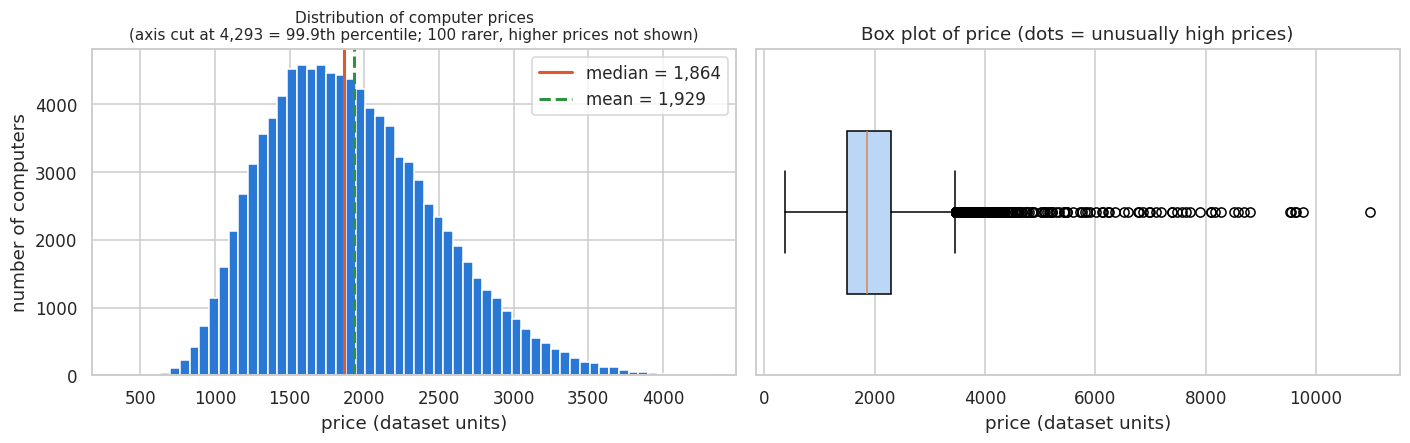

In [7]:
price_summary = df["price"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99])
print(price_summary.to_string(float_format=lambda v: f"{v:,.2f}"))
print(f"\nSkewness: {df['price'].skew():.2f}   |   prices <= 0: {(df['price'] <= 0).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
cut = df["price"].quantile(0.999)
ax[0].hist(df["price"], bins=60, range=(df["price"].min(), cut), color="#2a78d6", edgecolor="white")
ax[0].axvline(df["price"].median(), color="#e4572e", lw=2, label=f"median = {df['price'].median():,.0f}")
ax[0].axvline(df["price"].mean(), color="#2e933c", lw=2, ls="--", label=f"mean = {df['price'].mean():,.0f}")
ax[0].set_title(f"Distribution of computer prices\n(axis cut at {cut:,.0f} = 99.9th percentile; {(df['price'] > cut).sum()} rarer, higher prices not shown)", fontsize=10); ax[0].set_xlabel("price (dataset units)"); ax[0].set_ylabel("number of computers")
ax[0].legend()
ax[1].boxplot(df["price"], vert=False, widths=0.5, patch_artist=True, boxprops=dict(facecolor="#bcd6f5"))
ax[1].set_title("Box plot of price (dots = unusually high prices)"); ax[1].set_xlabel("price (dataset units)"); ax[1].set_yticks([])
plt.tight_layout(); plt.show()

**What this tells us.** Prices run from **372.99 to 10,984.99**, with a **mean of 1,928.76** and a **median of 1,863.99**. The middle half of all computers costs between **1,503.99 and 2,287.99**. The mean is slightly above the median and the skewness is **0.99**, so the distribution is **right-skewed**: most computers cost around 1,500–2,300, and a small number cost far more (the box plot's dots). No price is zero or negative, so no price needs repairing.

**Why it matters for RMSE:** RMSE squares each error, so a handful of very expensive computers that the model gets badly wrong can raise the RMSE noticeably (we see this in Section H).

## C.5 Numerical and categorical features

In [8]:
target = "price"
id_col = "ID"
candidate_cols = [c for c in df.columns if c not in (target, id_col)]

numeric_cols     = [c for c in candidate_cols if pd.api.types.is_numeric_dtype(df[c])]
categorical_cols = [c for c in candidate_cols if c not in numeric_cols]

print(f"Numerical features   ({len(numeric_cols)}): {numeric_cols}\n")
print(f"Categorical features ({len(categorical_cols)}): {categorical_cols}\n")
pd.DataFrame({"unique values": df[categorical_cols].nunique(),
              "most common": [df[c].mode()[0] for c in categorical_cols]}).sort_values("unique values", ascending=False)

Numerical features   (19): ['release_year', 'cpu_tier', 'cpu_cores', 'cpu_threads', 'cpu_base_ghz', 'cpu_boost_ghz', 'gpu_tier', 'vram_gb', 'ram_gb', 'storage_gb', 'storage_drive_count', 'display_size_in', 'refresh_hz', 'battery_wh', 'charger_watts', 'psu_watts', 'bluetooth', 'weight_kg', 'warranty_months']

Categorical features (13): ['device_type', 'brand', 'model', 'os', 'form_factor', 'cpu_brand', 'cpu_model', 'gpu_brand', 'gpu_model', 'storage_type', 'display_type', 'resolution', 'wifi']



,unique values,most common
model,99036,ASUS Slim R6S
cpu_model,26971,Apple M2 Pro
gpu_model,49,Apple Integrated
form_factor,10,Mainstream
brand,10,Lenovo
resolution,6,1920x1080
display_type,6,LED
storage_type,4,NVMe
os,4,Windows
wifi,4,Wi-Fi 6


**What this tells us.** There are **19 numeric** and **13 text (categorical)** candidate inputs. Two of the text columns, `model` (99,036 distinct values) and `cpu_model` (26,971), are almost unique per row — they behave like labels, not like specifications (see D.2). Every numeric column is a discrete specification (cores, GB, GHz, Wh …); `bluetooth` is a version number such as 5.2, which we keep as a number.

# D. Data Cleaning and Preprocessing

The data is already clean (no missing values, no duplicates), so cleaning focuses on three questions: *Are there unusual prices? Are some columns unsuitable as features? Is the data internally consistent?*

## D.1 Investigate unusual (very high) prices
We **do not delete** expensive computers just because they are expensive — a high-end gaming desktop *should* cost more. We only check whether the highest prices are explainable.

In [9]:
q1, q3 = df["price"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
n_high = (df["price"] > upper_fence).sum()
print(f"IQR rule upper fence = {upper_fence:,.0f}  ->  {n_high:,} computers ({n_high / len(df):.2%}) lie above it")
print(f"Cheapest price: {df['price'].min():,.2f}   |   Most expensive price: {df['price'].max():,.2f}\n")

show_cols = ["device_type", "brand", "cpu_tier", "gpu_model", "vram_gb", "ram_gb", "storage_gb", "resolution", "price"]
print("The 8 most expensive computers:")
display(df.nlargest(8, "price")[show_cols])

top = df[df["price"] > upper_fence]
print(f"Among the {len(top):,} 'high' computers: {(top['gpu_tier'] >= 5).mean():.0%} have GPU tier >= 5, "
      f"{(top['ram_gb'] >= 64).mean():.0%} have >= 64 GB RAM, {(top['cpu_tier'] >= 5).mean():.0%} have CPU tier >= 5.")
print(f"Whole dataset                   : {(df['gpu_tier'] >= 5).mean():.0%} have GPU tier >= 5, "
      f"{(df['ram_gb'] >= 64).mean():.0%} have >= 64 GB RAM, {(df['cpu_tier'] >= 5).mean():.0%} have CPU tier >= 5.")

IQR rule upper fence = 3,464  ->  976 computers (0.98%) lie above it
Cheapest price: 372.99   |   Most expensive price: 10,984.99

The 8 most expensive computers:


,device_type,brand,cpu_tier,gpu_model,vram_gb,ram_gb,storage_gb,resolution,price
40823,Laptop,Lenovo,5,RTX 40 90,16,96,2048,1920x1080,"10,984.99"
54591,Desktop,Apple,4,Apple Integrated,4,64,1024,2560x1440,"9,772.99"
64831,Desktop,HP,5,Arc A770,2,96,2048,3840x2160,"9,633.99"
75607,Desktop,MSI,4,Apple Integrated,4,64,4096,3840x2160,"9,621.99"
69792,Desktop,Apple,5,Apple Integrated,2,64,2048,3440x1440,"9,544.99"
36091,Laptop,Apple,5,Apple Integrated,0,96,512,1920x1080,"9,529.99"
28820,Laptop,Apple,3,Apple Integrated,4,32,512,1920x1080,"8,794.99"
95472,Laptop,Apple,5,Apple Integrated,2,64,2048,1920x1080,"8,701.99"


Among the 976 'high' computers: 86% have GPU tier >= 5, 94% have >= 64 GB RAM, 88% have CPU tier >= 5.
Whole dataset                   : 17% have GPU tier >= 5, 32% have >= 64 GB RAM, 18% have CPU tier >= 5.


**What this tells us.** Only **976 computers (0.98%)** are above the IQR upper fence of 3,464, and they are *explainable*: **86%** have a GPU of tier 5 or 6 (17% in the whole dataset), **94%** have at least 64 GB of RAM (32% overall) and **88%** have a CPU of tier 5 or 6 (18% overall). In other words, they are genuinely high-end machines, so they are **kept**.

A few of the very highest prices (for example computers with Apple integrated graphics priced at about 9,500–9,800) look higher than their specifications alone would suggest. We cannot prove they are errors, so we do **not** delete them; instead we measure honestly how the model copes with them in Section H.

## D.2 Choose the input features
Two columns are removed from the inputs, and a third is only a row label:

| Column | Decision | Reason |
|---|---|---|
| `ID` | **Dropped** | Just a row number — no hardware information. |
| `model` | **Dropped** | Almost every value is unique (a product name such as *"Dell Cube AXR"*). One-hot encoding it would add ~99,000 mostly-empty columns and let a model memorise rows instead of learning. |
| `cpu_model` | **Dropped** | ~27,000 unique codes. Its useful information is already captured by `cpu_brand`, `cpu_tier`, cores, threads and clock speeds. |
| `price` | **Target (y)** | What we predict. |

All other **30 columns are kept as inputs**, so the web app can ask for every one of them.

In [10]:
cardinality = df[["model", "cpu_model"]].nunique()
print("Unique values:  model =", f"{cardinality['model']:,}", "  cpu_model =", f"{cardinality['cpu_model']:,}", f"  (rows = {len(df):,})")

feature_cols = [c for c in candidate_cols if c not in ("model", "cpu_model")]
num_features = [c for c in feature_cols if c in numeric_cols]
cat_features = [c for c in feature_cols if c in categorical_cols]

X = df[feature_cols].copy()
y = df[target].copy()
print(f"\nInput features (X): {X.shape[1]} columns  ({len(num_features)} numeric + {len(cat_features)} categorical)")
print(f"Target (y)        : '{target}'   |   rows: {len(X):,}")

Unique values:  model = 99,036   cpu_model = 26,971   (rows = 100,000)

Input features (X): 30 columns  (19 numeric + 11 categorical)
Target (y)        : 'price'   |   rows: 100,000


## D.3 Check that the data is internally consistent
A quick sanity check that the specifications make physical sense (laptops have batteries and no PSU; desktops the opposite).

In [11]:
consistency = df.groupby("device_type").agg(
    rows=("price", "size"),
    battery_wh_min=("battery_wh", "min"), battery_wh_max=("battery_wh", "max"),
    psu_watts_min=("psu_watts", "min"),   psu_watts_max=("psu_watts", "max"),
    screen_in_min=("display_size_in", "min"), screen_in_max=("display_size_in", "max"),
    weight_kg_min=("weight_kg", "min"),   weight_kg_max=("weight_kg", "max"),
)
display(consistency)
print("cpu_boost_ghz >= cpu_base_ghz in every row:", bool((df["cpu_boost_ghz"] >= df["cpu_base_ghz"]).all()))
print("cpu_threads  >= cpu_cores     in every row:", bool((df["cpu_threads"] >= df["cpu_cores"]).all()))

,rows,battery_wh_min,battery_wh_max,psu_watts_min,psu_watts_max,screen_in_min,screen_in_max,weight_kg_min,weight_kg_max
device_type,,,,,,,,,
Desktop,40156,0,0,300,1200,24.00,34.00,4.00,16.00
Laptop,59844,50,99,0,0,13.30,17.30,0.92,3.14


cpu_boost_ghz >= cpu_base_ghz in every row: True
cpu_threads  >= cpu_cores     in every row: True


**What this tells us.** The data is internally consistent: laptops always have a battery (50–99 Wh) and no power supply, desktops the opposite (no battery, 300–1,200 W PSU); laptop screens are 13.3–17.3 in and 0.92–3.14 kg, desktop screens 24–34 in and 4–16 kg; and in every row the boost clock is at least the base clock and threads are at least cores. We reuse these facts in the web app so that users can only pick realistic combinations.

## D.4 Build the pre-processing pipeline (leakage-free)

Machine-learning algorithms need numbers, and several (Ridge, Elastic Net, SVR, neural networks) are sensitive to feature scale. The pipeline therefore does:

| Feature type | Steps | Why |
|---|---|---|
| Numeric (19) | Median imputation → **StandardScaler** | Fills any gaps and puts RAM (8–144) and clock speed (2–4.5) on the same scale. |
| Categorical (11) | Most-frequent imputation → **OneHotEncoder** | Turns text such as *"NVMe"* into 0/1 columns without inventing a fake order. `handle_unknown="ignore"` means a category never seen in training will not crash the model. |

**Avoiding data leakage.** The imputers, scaler and encoder live **inside** the scikit-learn `Pipeline`. In cross-validation they are **re-fitted on the training folds only** in every round and then applied to the validation fold, so the validation data never influences preprocessing.

In [12]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_features),
    ("cat", categorical_pipeline, cat_features),
])
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['release_year', 'cpu_tier', 'cpu_cores',
                                  'cpu_threads', 'cpu_base_ghz',
                                  'cpu_boost_ghz', 'gpu_tier', 'vram_gb',
                                  'ram_gb', 'storage_gb', 'storage_drive_count',
                                  'display_size_in', 'refresh_hz', 'battery_wh',
                                  'charger_watts', 'psu_watts', 'bluetooth',
                                  'weight_kg', 'warranty_months']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                   

# E. Exploratory Data Analysis (EDA)
Every chart below uses the real dataset values. Prices are in the dataset's own units (currency not stated).

## E.1 Laptops vs desktops

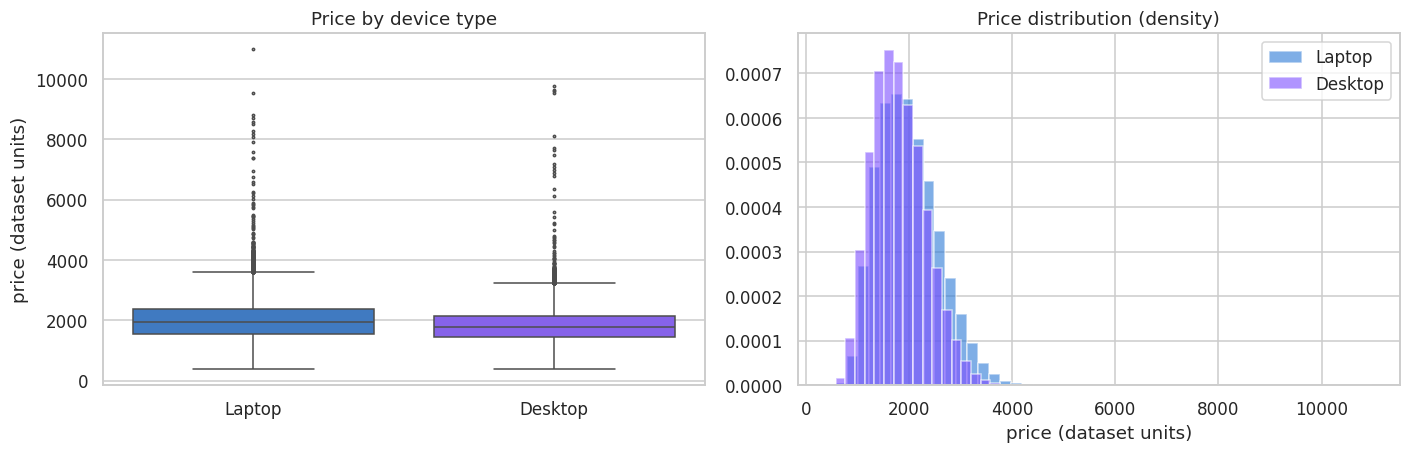

,count,mean,median,min,max
device_type,,,,,
Desktop,40156,"1,819.55","1,767.99",388.99,"9,772.99"
Laptop,59844,"2,002.05","1,934.99",372.99,"10,984.99"


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
order = ["Laptop", "Desktop"]
sns.boxplot(data=df, x="device_type", y="price", order=order, palette=["#2a78d6", "#7c4dff"], ax=ax[0], fliersize=1.5)
ax[0].set_title("Price by device type"); ax[0].set_xlabel(""); ax[0].set_ylabel("price (dataset units)")
for dev, color in zip(order, ["#2a78d6", "#7c4dff"]):
    ax[1].hist(df.loc[df.device_type == dev, "price"], bins=50, alpha=0.6, color=color, label=dev, density=True)
ax[1].set_title("Price distribution (density)"); ax[1].set_xlabel("price (dataset units)"); ax[1].legend()
plt.tight_layout(); plt.show()
display(df.groupby("device_type")["price"].agg(["count", "mean", "median", "min", "max"]))

**What this tells us.** On average **laptops cost more (mean 2,002.05, median 1,934.99) than desktops (mean 1,819.55, median 1,767.99)** — roughly 10% more. The two distributions overlap heavily and both have a long upper tail (most expensive laptop 10,984.99, desktop 9,772.99), so device type alone cannot predict price; the specifications matter more.

## E.2 RAM and storage versus price

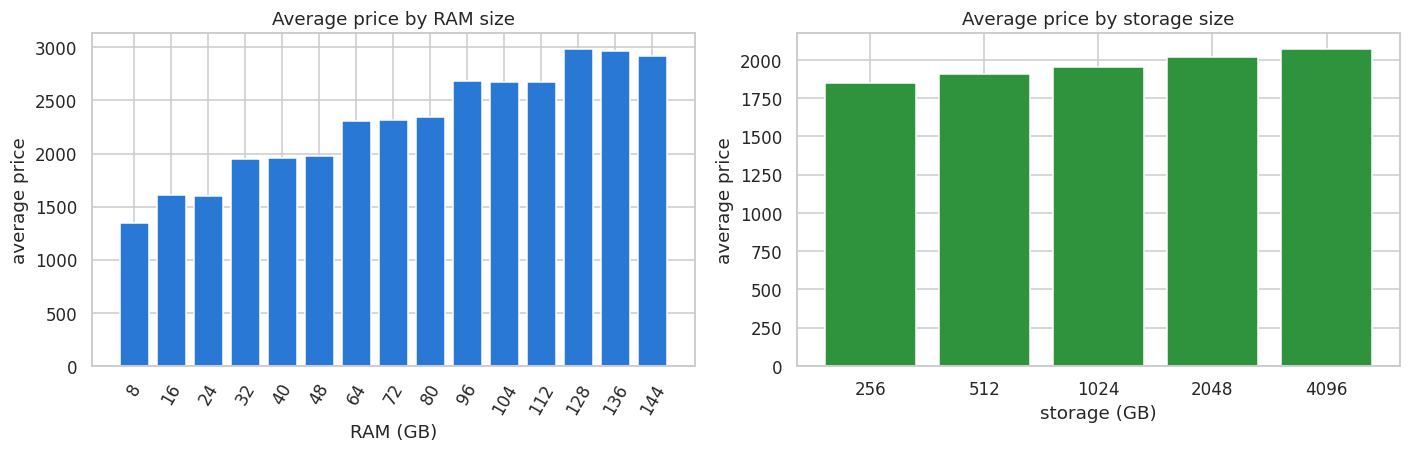

,count,mean
storage_type,,
HDD,15023,"1,846.46"
NVMe,45059,"1,942.52"
Hybrid,14981,"1,942.70"
SSD,24937,"1,945.13"


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ram_mean = df.groupby("ram_gb")["price"].mean()
ax[0].bar(ram_mean.index.astype(str), ram_mean.values, color="#2a78d6")
ax[0].set_title("Average price by RAM size"); ax[0].set_xlabel("RAM (GB)"); ax[0].set_ylabel("average price")
ax[0].tick_params(axis="x", rotation=60)
st_mean = df.groupby("storage_gb")["price"].mean()
ax[1].bar(st_mean.index.astype(str), st_mean.values, color="#2e933c")
ax[1].set_title("Average price by storage size"); ax[1].set_xlabel("storage (GB)"); ax[1].set_ylabel("average price")
plt.tight_layout(); plt.show()

display(df.groupby("storage_type")["price"].agg(["count", "mean"]).sort_values("mean"))

**What this tells us.** Average price rises strongly with RAM: from about **1,348 at 8 GB** to about **2,983 at 128 GB** (more than double). Neighbouring sizes sometimes cost almost the same (for example 96, 104 and 112 GB all average about 2,679), which suggests prices follow *build tiers* rather than a smooth per-gigabyte rule. Storage capacity matters much less: 256 GB averages 1,852 and 4,096 GB averages 2,070 (about 12% more). Among storage types, HDD is cheapest (1,846) while NVMe, Hybrid and SSD are almost the same (about 1,943–1,945).

*Caution:* RAM is strongly correlated with the CPU and GPU tier (correlation ≈ 0.90, see E.5), so part of the "RAM effect" is really "higher-end build" effect.

## E.3 CPU tier and GPU tier versus price

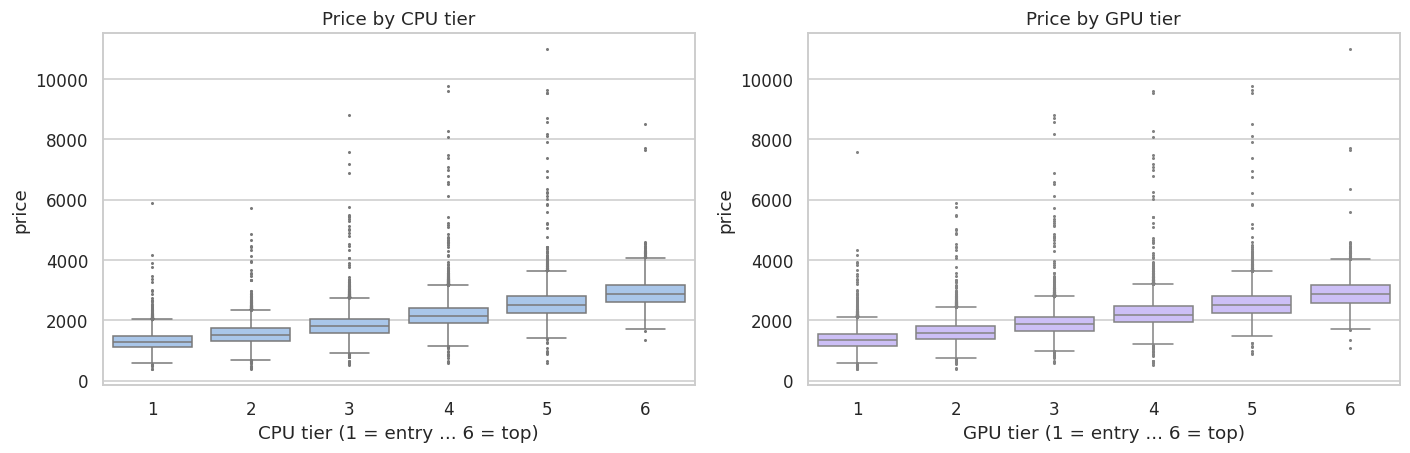

,count,mean
gpu_brand,,
Intel,10599,"1,839.30"
NVIDIA,54712,"1,873.30"
AMD,15767,"1,886.68"
Apple,18922,"2,174.32"


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
sns.boxplot(data=df, x="cpu_tier", y="price", color="#9ec5f4", ax=ax[0], fliersize=1)
ax[0].set_title("Price by CPU tier"); ax[0].set_xlabel("CPU tier (1 = entry ... 6 = top)")
sns.boxplot(data=df, x="gpu_tier", y="price", color="#c7b6ff", ax=ax[1], fliersize=1)
ax[1].set_title("Price by GPU tier"); ax[1].set_xlabel("GPU tier (1 = entry ... 6 = top)")
plt.tight_layout(); plt.show()

gpu_brand_mean = df.groupby("gpu_brand")["price"].agg(["count", "mean"]).sort_values("mean")
display(gpu_brand_mean)

**What this tells us.** Average price climbs steadily with the CPU tier (**1,314 at tier 1 → 2,910 at tier 6**) and with the GPU tier (**1,358 → 2,883**), by roughly 300 per tier. The boxes overlap, so a tier is a strong hint but not an exact price. By GPU brand, Apple's integrated graphics have the highest average (2,174) and Intel the lowest (1,839); part of this difference comes from which tiers each brand is sold in.

## E.4 Brand, display and release-year comparisons

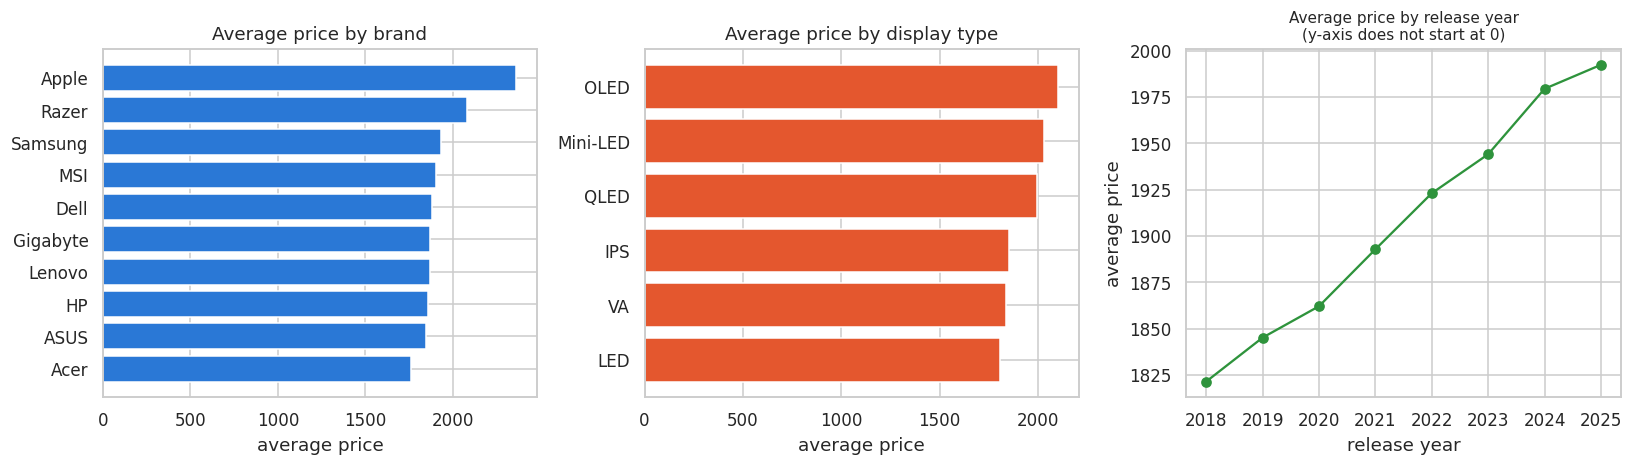

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
b = df.groupby("brand")["price"].mean().sort_values()
ax[0].barh(b.index, b.values, color="#2a78d6"); ax[0].set_title("Average price by brand"); ax[0].set_xlabel("average price")
d = df.groupby("display_type")["price"].mean().sort_values()
ax[1].barh(d.index, d.values, color="#e4572e"); ax[1].set_title("Average price by display type"); ax[1].set_xlabel("average price")
yr = df.groupby("release_year")["price"].mean()
ax[2].plot(yr.index, yr.values, marker="o", color="#2e933c"); ax[2].set_title("Average price by release year\n(y-axis does not start at 0)", fontsize=10)
ax[2].set_xlabel("release year"); ax[2].set_ylabel("average price")
plt.tight_layout(); plt.show()

**What this tells us.** Apple computers have the highest average price (**2,362**), followed by Razer (2,080); Acer is the lowest (1,760). OLED panels average 2,102 versus 1,809 for plain LED. Prices also rise steadily with release year, from **1,821 (2018) to 1,992 (2025)** — about 9% in total (note that the line chart's y-axis does not start at zero, which makes the slope look steeper than it is).

## E.5 Correlation heatmap (numerical features)

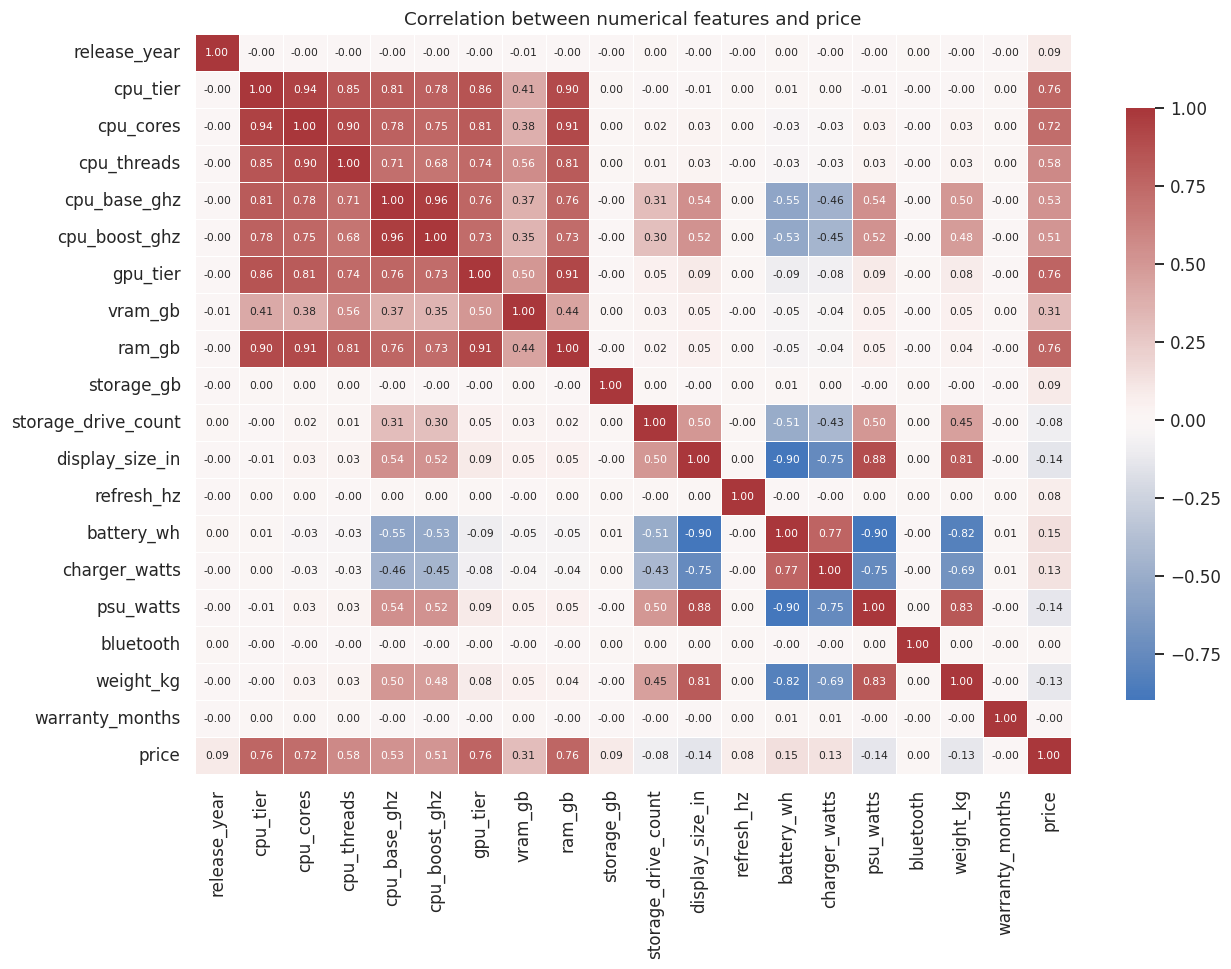

Correlation with price (strongest first):
gpu_tier        0.76
cpu_tier        0.76
ram_gb          0.76
cpu_cores       0.72
cpu_threads     0.58
cpu_base_ghz    0.53
cpu_boost_ghz   0.51
vram_gb         0.31


In [17]:
corr = df[num_features + [target]].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.4, cbar_kws={"shrink": 0.8})
plt.title("Correlation between numerical features and price"); plt.tight_layout(); plt.show()

print("Correlation with price (strongest first):")
print(corr[target].drop(target).sort_values(key=abs, ascending=False).head(8).round(2).to_string())

**What this tells us.** The inputs most correlated with price are **GPU tier, CPU tier and RAM (all about 0.76)**, then CPU cores (0.72). Screen size, PSU watts and weight are weakly *negatively* correlated simply because desktops (large screens, heavy) are cheaper on average. Bluetooth version and warranty have almost no linear relationship with price.

The heat map also shows that the hardware inputs are **strongly correlated with each other** (for example CPU tier and cores 0.94, RAM and GPU tier 0.91, CPU tier and RAM 0.90). This is called *multicollinearity*. It makes the individual weights of linear models hard to interpret, and it is one reason to use **regularised** models such as Ridge.

# F. Train, Validate and Test Correctly

**Strategy: 10-Fold Cross-Validation on the full labelled dataset** (as required by the assignment).

1. Shuffle the 100,000 labelled computers (fixed seed `42`) and split them into **10 equal folds** of 10,000.
2. In each of 10 rounds, **train on 9 folds (90,000 computers)** and **validate on the remaining fold (10,000 computers)**.
3. Every computer is therefore used for validation **exactly once**, and the validation computers are never used to fit the preprocessing or the model in that round.
4. The **same folds** are used for all 5 algorithms, so each is tested on exactly the same computers (a fair comparison).

**About the official test file.** `computer_prices_test.csv` has no `price` column, so no metrics can (or will) be computed on it. It is used only to create the optional Kaggle submission in Section K.

> **A note on cross-validation vs the final model.** The 10 models built during cross-validation are only *measuring sticks* used to choose an algorithm. The final model (Section I) is re-trained on all 100,000 computers.

In [18]:
K = 10
kfold = KFold(n_splits=K, shuffle=True, random_state=RANDOM_STATE)
folds = list(kfold.split(X))                       # the same folds for every algorithm

fold_info = pd.DataFrame([{
    "Fold": i, "Training rows": len(tr), "Validation rows": len(va),
    "Avg price (validation)": y.iloc[va].mean(), "Max price (validation)": y.iloc[va].max(),
} for i, (tr, va) in enumerate(folds, start=1)]).set_index("Fold")
fold_info

,Training rows,Validation rows,Avg price (validation),Max price (validation)
Fold,,,,
1,90000,10000,"1,931.84","6,514.99"
2,90000,10000,"1,924.48","8,579.99"
3,90000,10000,"1,920.13","8,701.99"
4,90000,10000,"1,925.03","9,621.99"
5,90000,10000,"1,935.53","10,984.99"
6,90000,10000,"1,934.35","9,633.99"
7,90000,10000,"1,927.07","7,396.99"
8,90000,10000,"1,936.18","9,529.99"
9,90000,10000,"1,929.95","7,576.99"


**What this tells us.** Every round trains on **90,000** and validates on **10,000** computers. The average validation price is almost the same in all folds (1,920–1,936), so the folds are comparable. The *most expensive* validation computer differs a lot (from 6,515 in fold 1 to **10,984.99 in fold 5**). Because RMSE squares errors, we expect fold 5 to have the largest RMSE — and it does (Section H.3).

# G. Regression Models

Five algorithms are compared. **None of them is Linear Regression, KNN, Decision Tree, Random Forest or Gradient Boosting.**

| # | Algorithm | How it predicts a price | Why it is suitable here |
|---|---|---|---|
| 1 | **Ridge Regression** | A weighted sum of the features, with a penalty that keeps the weights small | Fast, stable with many one-hot columns that overlap (e.g. `cpu_cores` & `cpu_threads`) |
| 2 | **Elastic Net** | Weighted sum with a mix of *L1* (can switch features off) and *L2* penalties | Shows whether removing/shrinking features helps |
| 3 | **Bayesian Ridge** *(extra, non-forbidden)* | A weighted sum whose penalty strength is **learned automatically from the data** | Needs no manual tuning of the regularisation; a principled third linear model for comparison |
| 4 | **Support Vector Regression (SVR, RBF kernel)** | Fits a smooth curved surface; errors smaller than a margin (ε) are ignored | Captures non-linear relationships — but training time grows very fast with rows (see note) |
| 5 | **Neural network (MLPRegressor)** | A feed-forward network with two hidden layers (128 → 64 neurons) | Learns non-linear interactions (e.g. a strong GPU *and* much RAM) |

**Settings.** All models use fixed, sensible settings (no hyper-parameter search) so the comparison stays simple and fair. For **SVR and the neural network** the *target price is standardised* inside the pipeline (`TransformedTargetRegressor`) because these models behave badly when the target is in the thousands; predictions are converted back to price units automatically.

> ### ⚠ Important disclosure — SVR is trained on a subset
> Kernel SVR needs memory and time that grow roughly with the **square of the number of training rows**. A full 90,000-row SVR in every one of 10 folds would take hours (and may exhaust Colab's RAM). Therefore, in each fold **SVR is trained on a random 10,000-row sample of that fold's 90,000 training rows**, but it is **validated on the full 10,000-row validation fold — exactly the same rows as every other model**. The other four algorithms use all 90,000 training rows. This is shown in the results table (column *Training rows per fold*) and should be kept in mind when comparing SVR with the others.

In [19]:
SVR_TRAIN_ROWS = 10_000                            # SVR is trained on this many rows per fold (disclosed above)

algorithms = {
    "Ridge Regression": Ridge(alpha=1.0, random_state=RANDOM_STATE),
    "Elastic Net": ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=5000, random_state=RANDOM_STATE),
    "Bayesian Ridge": BayesianRidge(),
    "SVR (RBF, 10k subset)": TransformedTargetRegressor(
        regressor=SVR(kernel="rbf", C=3.0, epsilon=0.1, gamma="scale"), transformer=StandardScaler()),
    "Neural Network (MLP)": TransformedTargetRegressor(
        regressor=MLPRegressor(hidden_layer_sizes=(128, 64), activation="relu", early_stopping=True,
                               max_iter=200, random_state=RANDOM_STATE),
        transformer=StandardScaler()),
}
rows_per_fold = {name: (SVR_TRAIN_ROWS if name.startswith("SVR") else len(folds[0][0])) for name in algorithms}

print("Algorithms to compare:")
for number, name in enumerate(algorithms, start=1):
    print(f"  {number}. {name:<24} trained on {rows_per_fold[name]:,} rows per fold")

Algorithms to compare:
  1. Ridge Regression         trained on 90,000 rows per fold
  2. Elastic Net              trained on 90,000 rows per fold
  3. Bayesian Ridge           trained on 90,000 rows per fold
  4. SVR (RBF, 10k subset)    trained on 10,000 rows per fold
  5. Neural Network (MLP)     trained on 90,000 rows per fold


# H. Model Evaluation

## H.1 Metrics used (beginner-friendly)

| Metric | Meaning | Better is |
|---|---|---|
| **RMSE** (Root Mean Squared Error) | The typical size of a prediction error, in price units. It squares errors first, so **big mistakes are punished more**. **Main ranking metric** in this assignment. | Lower |
| **MAE** (Mean Absolute Error) | The *average* size of the error in price units — easier to read; every mistake counts equally. | Lower |
| **R²** | The share of the price variation the model explains: 1.0 = perfect, 0 = no better than always guessing the average price. | Higher |

If a model has MAE = 150, then on average its predictions are about 150 price units away from the true price.

## H.2 Run 10-fold cross-validation for all 5 algorithms
For every fold we (1) clone a fresh untrained pipeline, (2) train it on the 9 training folds, (3) predict the validation fold, and (4) record RMSE, MAE, R² and the time taken. The progress bar shows elapsed time and the estimated time remaining (5 algorithms × 10 folds = 50 steps).

In [20]:
fold_scores = {name: {"rmse": [], "mae": [], "r2": [], "time": []} for name in algorithms}
oof_pred = {name: np.zeros(len(y)) for name in algorithms}      # out-of-fold predictions (each row predicted once)

total_steps = len(algorithms) * K
with tqdm(total=total_steps, unit="fold") as bar:
    for name, algo in algorithms.items():
        pipeline = Pipeline([("preprocessor", preprocessor), ("regressor", algo)])
        for fold_no, (tr_idx, va_idx) in enumerate(folds, start=1):
            bar.set_description(f"{name}, fold {fold_no}/{K}")
            if name.startswith("SVR"):                               # disclosed subset for SVR only
                rng = np.random.RandomState(RANDOM_STATE + fold_no)
                tr_idx = rng.choice(tr_idx, size=SVR_TRAIN_ROWS, replace=False)
            model = clone(pipeline)                                  # fresh, untrained copy
            t0 = time.time()
            model.fit(X.iloc[tr_idx], y.iloc[tr_idx])                # preprocessing is fitted on training rows only
            pred = model.predict(X.iloc[va_idx])                     # validation fold (unseen)
            elapsed = time.time() - t0

            oof_pred[name][va_idx] = pred
            fold_scores[name]["rmse"].append(np.sqrt(mean_squared_error(y.iloc[va_idx], pred)))
            fold_scores[name]["mae"].append(mean_absolute_error(y.iloc[va_idx], pred))
            fold_scores[name]["r2"].append(r2_score(y.iloc[va_idx], pred))
            fold_scores[name]["time"].append(elapsed)
            bar.update(1)
        tqdm.write(f"{name:<24} mean RMSE = {np.mean(fold_scores[name]['rmse']):>8,.2f}   "
                   f"total time = {np.sum(fold_scores[name]['time']):>6.1f} s")
    bar.set_description("Done")
print(f"\n{K}-fold cross-validation finished for all {len(algorithms)} algorithms.")

Ridge Regression, fold 10/10 20%|####                | 10/50 [00:05<00:23]
Ridge Regression         mean RMSE =   220.71   total time =    5.9 s
Elastic Net, fold 10/10      40%|########            | 20/50 [00:40<01:01]
Elastic Net              mean RMSE =   221.01   total time =   34.9 s
Bayesian Ridge, fold 10/10   60%|############        | 30/50 [00:56<00:37]
Bayesian Ridge           mean RMSE =   220.71   total time =   15.8 s
SVR (RBF, 10k subset), fold 10/10 80%|################    | 40/50 [04:09<01:02]
SVR (RBF, 10k subset)    mean RMSE =   231.63   total time =  192.4 s
Neural Network (MLP), fold 10/10100%|####################| 50/50 [05:38<00:00]
Neural Network (MLP)     mean RMSE =   217.64   total time =   89.2 s

10-fold cross-validation finished for all 5 algorithms.


## H.3 RMSE of every algorithm on every fold
Each row is one cross-validation round. The **lowest RMSE in each row** (best algorithm on that fold) is highlighted in green.

In [21]:
per_fold_rmse = pd.DataFrame({n: s["rmse"] for n, s in fold_scores.items()})
per_fold_rmse.index = [f"Fold {i}" for i in range(1, K + 1)]
per_fold_rmse.index.name = "Fold"
(per_fold_rmse.style.format("{:,.2f}")
    .highlight_min(axis=1, props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

,Ridge Regression,Elastic Net,Bayesian Ridge,"SVR (RBF, 10k subset)",Neural Network (MLP)
Fold,,,,,
Fold 1,203.69,203.93,203.69,215.13,200.51
Fold 2,201.83,202.01,201.82,214.53,197.99
Fold 3,216.20,216.30,216.18,228.13,211.80
Fold 4,210.70,211.23,210.72,223.33,206.96
Fold 5,269.45,269.89,269.45,277.68,267.38
Fold 6,246.05,246.35,246.04,255.54,244.32
Fold 7,206.80,207.07,206.80,219.06,204.45
Fold 8,232.82,232.89,232.81,242.83,229.64
Fold 9,199.04,199.61,199.05,210.14,196.00


## H.4 Model-comparison table
| Column | Meaning |
|---|---|
| **Mean RMSE** | Average RMSE over the 10 folds — the **ranking metric** (lower is better) |
| **Std RMSE** | Spread of RMSE over the folds (small = consistent) |
| **Mean MAE / Mean R²** | Average MAE and R² over the folds |
| **RMSE % of avg price** | Mean RMSE ÷ average price — puts the error in context |
| **Time (s)** | Total train + predict time over all 10 folds |

In [22]:
avg_price = y.mean()
summary = pd.DataFrame({
    "Mean RMSE": per_fold_rmse.mean(),
    "Std RMSE": per_fold_rmse.std(),
    "Mean MAE": pd.Series({n: np.mean(s["mae"]) for n, s in fold_scores.items()}),
    "Mean R2": pd.Series({n: np.mean(s["r2"]) for n, s in fold_scores.items()}),
    "RMSE % of avg price": per_fold_rmse.mean() / avg_price * 100,
    "Time (s)": pd.Series({n: np.sum(s["time"]) for n, s in fold_scores.items()}),
    "Training rows per fold": pd.Series(rows_per_fold),
}).sort_values("Mean RMSE")
summary.insert(0, "Rank", range(1, len(summary) + 1))
summary.index.name = "Algorithm"

print(f"Average price in the dataset: {avg_price:,.2f} (dataset units)\n")
(summary.style
    .format({"Mean RMSE": "{:,.2f}", "Std RMSE": "{:,.2f}", "Mean MAE": "{:,.2f}", "Mean R2": "{:.4f}",
             "RMSE % of avg price": "{:.1f}%", "Time (s)": "{:,.1f}", "Training rows per fold": "{:,}"})
    .highlight_min(subset=["Mean RMSE", "Mean MAE"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;")
    .highlight_max(subset=["Mean R2"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

Average price in the dataset: 1,928.76 (dataset units)



,Rank,Mean RMSE,Std RMSE,Mean MAE,Mean R2,RMSE % of avg price,Time (s),Training rows per fold
Algorithm,,,,,,,,
Neural Network (MLP),1,217.64,23.09,141.33,0.8587,11.3%,89.2,"90,000"
Bayesian Ridge,2,220.71,22.59,144.50,0.8547,11.4%,15.8,"90,000"
Ridge Regression,3,220.71,22.59,144.51,0.8547,11.4%,5.9,"90,000"
Elastic Net,4,221.01,22.60,144.64,0.8543,11.5%,34.9,"90,000"
"SVR (RBF, 10k subset)",5,231.63,21.31,154.15,0.8402,12.0%,192.4,"10,000"


**Reading the table.**
- The **neural network (MLP)** has the lowest mean RMSE (**217.64**) and MAE (**141.33**) and the highest R² (**0.8587**), i.e. it explains about 86% of the variation in price.
- **Ridge** and **Bayesian Ridge** are practically identical (RMSE 220.71) — expected, because Bayesian Ridge is a ridge model whose penalty is learned automatically. **Elastic Net** is almost the same (221.01), so shrinking or removing features brings no benefit here.
- **SVR** is last (231.63), **but it was trained on only 10,000 rows per fold instead of 90,000**, so this is *not* a fair verdict on kernel methods; it mainly shows the price of the subset. It was also the slowest model in total (196.7 s) despite using nine times fewer rows.
- All five algorithms lie within a narrow band: the mean RMSE is only **11.3%–12.0% of the average price**. The gap between the best and the fourth model is about 1.5%.
- Speed: Ridge needs 5.9 s for all 10 folds, the neural network 89.9 s.

## H.5 Model-performance charts

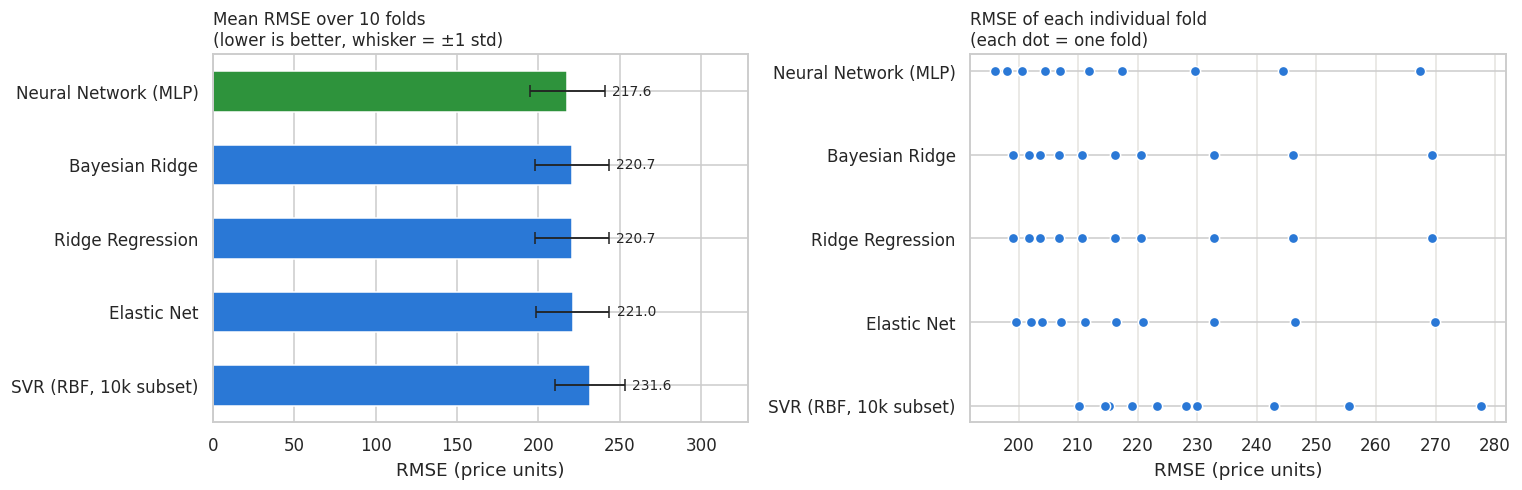

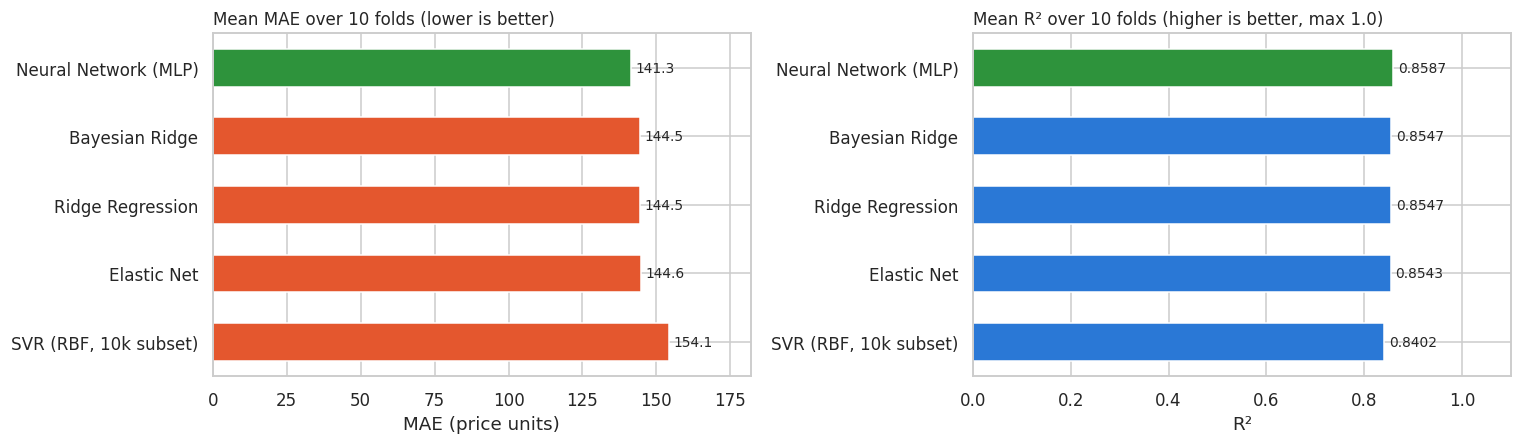

In [23]:
BLUE, ORANGE, GREEN, GRID = "#2a78d6", "#e4572e", "#2e933c", "#e4e3df"
order = summary.index.tolist()                       # best first
pos = np.arange(len(order))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# Chart 1: mean RMSE (+/- 1 std) -------------------------------------------------
m, s = summary["Mean RMSE"], summary["Std RMSE"]
axes[0].barh(pos, m, color=[GREEN if i == 0 else BLUE for i in range(len(order))],
             xerr=s, error_kw=dict(ecolor="#222", capsize=4, elinewidth=1.2), height=0.55)
for i, n in enumerate(order):
    axes[0].text(m[n] + s[n] + m.max() * 0.02, i, f"{m[n]:,.1f}", va="center", fontsize=9)
axes[0].set_yticks(pos, order); axes[0].invert_yaxis(); axes[0].set_xlim(0, (m + s).max() * 1.3)
axes[0].set_title("Mean RMSE over 10 folds\n(lower is better, whisker = ±1 std)", loc="left", fontsize=11)
axes[0].set_xlabel("RMSE (price units)")

# Chart 2: RMSE of every fold ----------------------------------------------------
for i, n in enumerate(order):
    axes[1].scatter(per_fold_rmse[n], np.full(K, i), s=45, color=BLUE, edgecolor="white", zorder=3)
axes[1].set_yticks(pos, order); axes[1].invert_yaxis()
axes[1].set_title("RMSE of each individual fold\n(each dot = one fold)", loc="left", fontsize=11)
axes[1].set_xlabel("RMSE (price units)"); axes[1].grid(axis="x", color=GRID)
plt.tight_layout(); plt.show()

# MAE and R2 ----------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
mae = summary["Mean MAE"]; r2 = summary["Mean R2"]
axes[0].barh(pos, mae, color=[GREEN if i == 0 else ORANGE for i in range(len(order))], height=0.55)
for i, n in enumerate(order):
    axes[0].text(mae[n] + mae.max() * 0.01, i, f"{mae[n]:,.1f}", va="center", fontsize=9)
axes[0].set_yticks(pos, order); axes[0].invert_yaxis(); axes[0].set_xlim(0, mae.max() * 1.18)
axes[0].set_title("Mean MAE over 10 folds (lower is better)", loc="left", fontsize=11); axes[0].set_xlabel("MAE (price units)")
axes[1].barh(pos, r2, color=[GREEN if i == 0 else BLUE for i in range(len(order))], height=0.55)
for i, n in enumerate(order):
    axes[1].text(r2[n] + 0.01, i, f"{r2[n]:.4f}", va="center", fontsize=9)
axes[1].set_yticks(pos, order); axes[1].invert_yaxis(); axes[1].set_xlim(0, 1.1)
axes[1].set_title("Mean R² over 10 folds (higher is better, max 1.0)", loc="left", fontsize=11); axes[1].set_xlabel("R²")
plt.tight_layout(); plt.show()

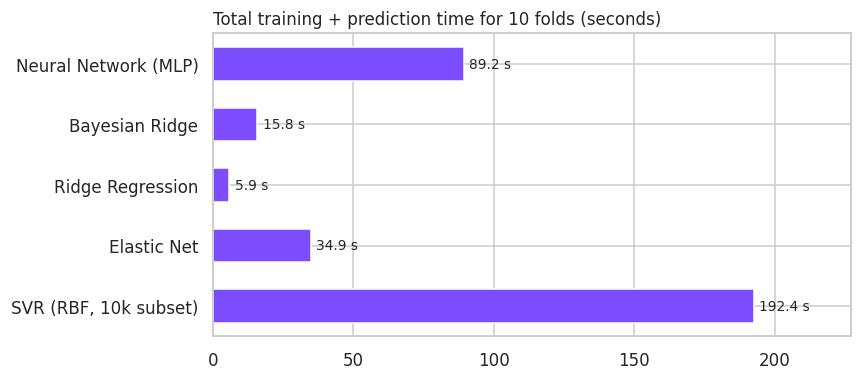

In [24]:
fig, ax = plt.subplots(figsize=(8, 3.6))
t = summary["Time (s)"]
ax.barh(pos, t, color="#7c4dff", height=0.55)
for i, n in enumerate(order):
    ax.text(t[n] + t.max() * 0.01, i, f"{t[n]:,.1f} s", va="center", fontsize=9)
ax.set_yticks(pos, order); ax.invert_yaxis(); ax.set_xlim(0, t.max() * 1.18)
ax.set_title("Total training + prediction time for 10 folds (seconds)", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

**Reading the charts.** The fold-to-fold spread (about ±22 RMSE units) is **much larger than the differences between algorithms**, and the dots show *the same fold pattern for every algorithm*: fold 5 is the hardest for all of them (RMSE about 267–278) because it contains the single most expensive computer (10,984.99), which no model predicts well. This is why we compare algorithms **fold by fold** (paired comparison in H.6) instead of only looking at the averages. MAE and R² give the same ranking as RMSE.

## H.6 Select the final model
The model is chosen from the **validation results**, not arbitrarily: lowest **mean RMSE** (the assignment's metric), then checked against MAE, R², consistency across folds and computing cost.

In [25]:
best_name = summary.index[0]
runner_up = summary.index[1]
best = summary.loc[best_name]

print(f"Selected model : {best_name}")
print(f"Mean RMSE      : {best['Mean RMSE']:,.2f}  (± {best['Std RMSE']:,.2f} over folds)  = {best['RMSE % of avg price']:.1f}% of the average price")
print(f"Mean MAE       : {best['Mean MAE']:,.2f}")
print(f"Mean R²        : {best['Mean R2']:.4f}")
print(f"Total CV time  : {best['Time (s)']:,.1f} s for 10 folds")

# Paired comparison with the runner-up: how many folds does the winner win?
diff = per_fold_rmse[runner_up] - per_fold_rmse[best_name]
print(f"\n{best_name} beats {runner_up} on {int((diff > 0).sum())} of {K} folds "
      f"(average advantage {diff.mean():,.2f}, std {diff.std():,.2f}).")

Selected model : Neural Network (MLP)
Mean RMSE      : 217.64  (± 23.09 over folds)  = 11.3% of the average price
Mean MAE       : 141.33
Mean R²        : 0.8587
Total CV time  : 89.2 s for 10 folds

Neural Network (MLP) beats Bayesian Ridge on 10 of 10 folds (average advantage 3.07, std 0.82).


**Why the neural network is selected.** It has the best mean RMSE, MAE and R², and it beats the runner-up on **every one of the 10 folds** (average advantage about 3 RMSE units, about 1.4%).

**Honest caveats.**
- The advantage is small. A plain Ridge model is almost as accurate, 15 times faster to cross-validate and easier to explain. We still choose the neural network because the assignment's metric (RMSE) ranks it first and its cost is affordable (the final model trains in about 9 seconds and the saved file is only about 0.6 MB).
- We choose the best of five models using the same cross-validation folds that we report, which can make the winner look very slightly better than it is. With only five untuned models and 100,000 rows this effect is tiny, but it is why the **official Kaggle leaderboard score** (Section K.1) would be the only truly independent test.

## H.7 Actual vs predicted (selected model)
Each point is one computer from the **out-of-fold** predictions — the prediction was made by a model that **had not seen that computer**. A perfect model would put every point on the dashed diagonal. (5,000 randomly chosen points are plotted to keep the chart readable.)

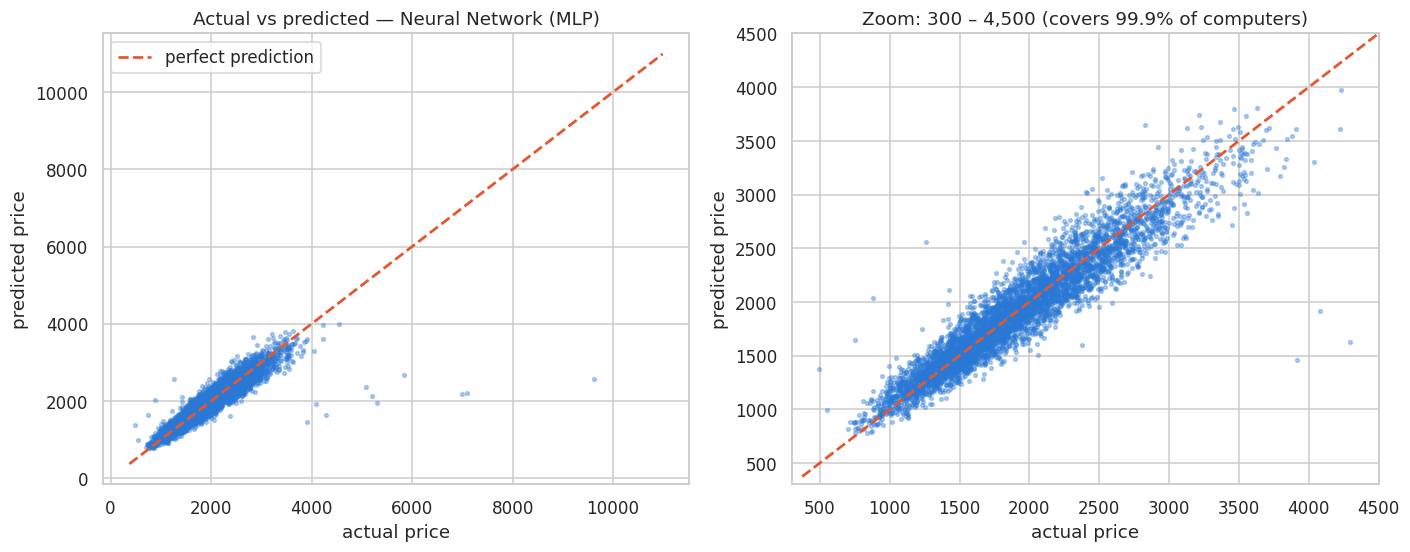

Share of computers priced within 4,500: 99.92%


In [26]:
y_true = y.values
y_hat = oof_pred[best_name]
sample = np.random.RandomState(0).choice(len(y_true), 5000, replace=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
ax[0].scatter(y_true[sample], y_hat[sample], s=6, alpha=0.35, color=BLUE)
lims = [min(y_true.min(), y_hat.min()), max(y_true.max(), y_hat.max())]
ax[0].plot(lims, lims, "--", color=ORANGE, lw=1.8, label="perfect prediction")
ax[0].set_title(f"Actual vs predicted — {best_name}"); ax[0].set_xlabel("actual price"); ax[0].set_ylabel("predicted price"); ax[0].legend()

# zoomed to the range where most computers are
ax[1].scatter(y_true[sample], y_hat[sample], s=6, alpha=0.35, color=BLUE)
ax[1].plot(lims, lims, "--", color=ORANGE, lw=1.8)
ax[1].set_xlim(300, 4500); ax[1].set_ylim(300, 4500)
ax[1].set_title("Zoom: 300 – 4,500 (covers 99.9% of computers)"); ax[1].set_xlabel("actual price"); ax[1].set_ylabel("predicted price")
plt.tight_layout(); plt.show()
print(f"Share of computers priced within 4,500: {(y_true <= 4500).mean():.2%}")

## H.8 Residual plot (selected model)
A **residual** = actual − predicted. Good models have residuals scattered randomly around zero with no pattern.

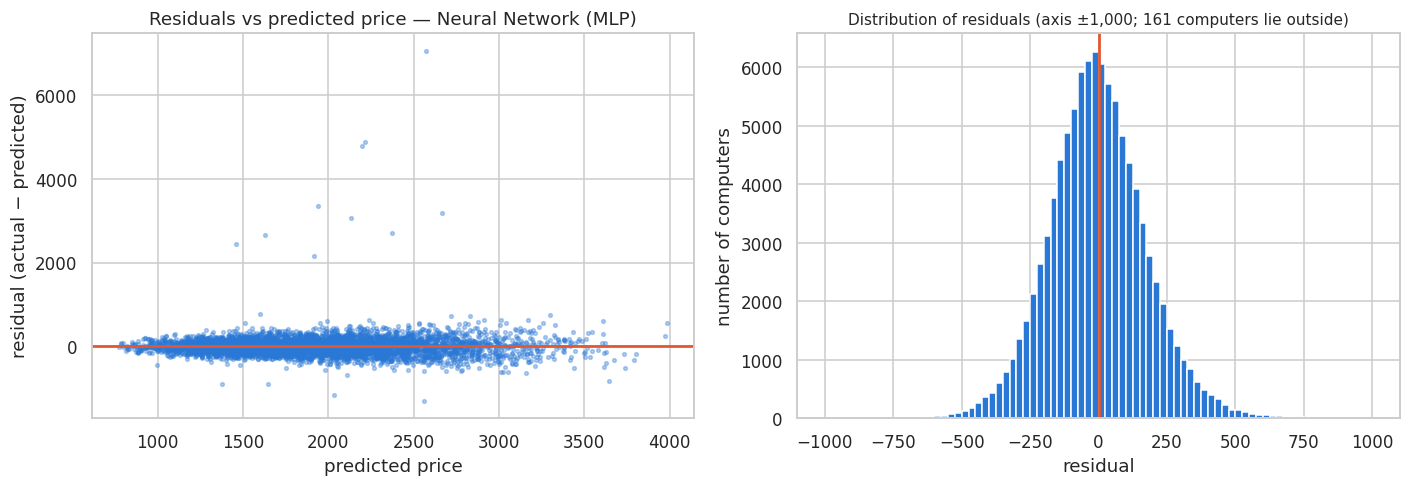

Mean residual: 1.02   |   Std of residuals: 218.74
Within ±200 of the true price: 76.2%   |   within ±400: 96.8%


,computers,mean residual (actual - predicted),MAE
"< 1,500",24782,-57.60,108.82
"1,500-2,500",59156,-6.59,134.24
"2,500-3,500",15198,86.70,188.89
"3,500-4,500",786,374.70,403.86
"> 4,500",78,"3,939.06","3,939.06"


In [27]:
residuals = y_true - y_hat
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].scatter(y_hat[sample], residuals[sample], s=6, alpha=0.35, color=BLUE)
ax[0].axhline(0, color=ORANGE, lw=1.8)
ax[0].set_title(f"Residuals vs predicted price — {best_name}"); ax[0].set_xlabel("predicted price"); ax[0].set_ylabel("residual (actual − predicted)")
outside = int((np.abs(residuals) > 1000).sum())
ax[1].hist(residuals, bins=80, range=(-1000, 1000), color=BLUE, edgecolor="white")
ax[1].axvline(0, color=ORANGE, lw=1.8)
ax[1].set_title(f"Distribution of residuals (axis ±1,000; {outside} computers lie outside)", fontsize=10)
ax[1].set_xlabel("residual"); ax[1].set_ylabel("number of computers")
plt.tight_layout(); plt.show()
print(f"Mean residual: {residuals.mean():,.2f}   |   Std of residuals: {residuals.std():,.2f}")
print(f"Within ±200 of the true price: {(np.abs(residuals) <= 200).mean():.1%}   |   within ±400: {(np.abs(residuals) <= 400).mean():.1%}")

# Is the model equally accurate for cheap and for very expensive computers?
bands = pd.cut(pd.Series(y_true), [0, 1500, 2500, 3500, 4500, np.inf], labels=["< 1,500", "1,500-2,500", "2,500-3,500", "3,500-4,500", "> 4,500"])
band_table = pd.DataFrame({"computers": pd.Series(residuals).groupby(bands).size(),
                           "mean residual (actual - predicted)": pd.Series(residuals).groupby(bands).mean(),
                           "MAE": pd.Series(np.abs(residuals)).groupby(bands).mean()})
display(band_table)

**What this tells us.** The residuals are centred on zero (mean ≈ 1), so the model is not systematically too high or too low *overall*. About **76%** of predictions are within ±200 of the true price and **97%** within ±400. The left plot shows a "funnel": the spread of the errors grows for computers with higher predicted prices, so the model is **less precise for expensive computers**.

The table in the last cell confirms this. MAE grows from about **109** for computers under 1,500 to about **189** for 2,500–3,500 and **404** for 3,500–4,500. The 78 computers priced above 4,500 (0.08% of the data) are predicted about **3,939 too low on average** — the model cannot explain these extreme prices from the specifications, and they are the reason RMSE (≈ 218) is well above MAE (≈ 141). The positive mean residual at the high end (and negative at the low end) shows the model "pulls toward the middle".

## H.9 Which inputs does the model rely on? (permutation importance)
Permutation importance shuffles one input at a time and measures how much the error increases. A big increase means the model **relies on that input to predict**. This describes the *model's behaviour*, **not a cause-and-effect rule about the market**. It is computed on a 5,000-row sample using a model trained on 90,000 rows of fold 1 and evaluated on that fold's validation rows.

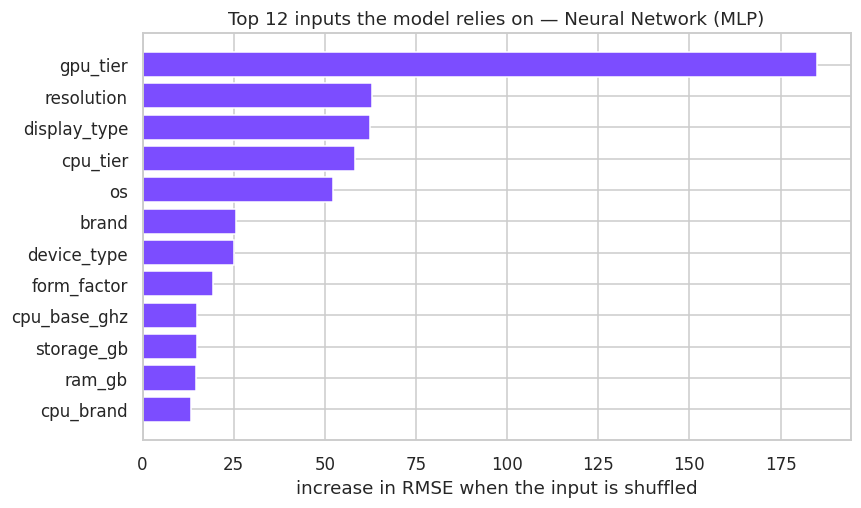

,RMSE increase
gpu_tier,184.92
resolution,62.87
display_type,62.35
cpu_tier,58.23
os,52.23
brand,25.76
device_type,25.09
form_factor,19.32
cpu_base_ghz,14.98
storage_gb,14.93


In [28]:
tr_idx, va_idx = folds[0]
imp_model = clone(Pipeline([("preprocessor", preprocessor), ("regressor", algorithms[best_name])]))
imp_model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
va_sample = np.random.RandomState(1).choice(va_idx, 5000, replace=False)
perm = permutation_importance(imp_model, X.iloc[va_sample], y.iloc[va_sample], n_repeats=3,
                              random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error")
importance = (pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False))
top = importance.head(12)[::-1]
plt.figure(figsize=(8, 4.8))
plt.barh(top.index, top.values, color="#7c4dff")
plt.xlabel("increase in RMSE when the input is shuffled"); plt.title(f"Top 12 inputs the model relies on — {best_name}")
plt.tight_layout(); plt.show()
importance.head(10).round(2).to_frame("RMSE increase")

**What this tells us.** The model relies most on **`gpu_tier`** (shuffling it raises RMSE by about 185), followed by `resolution`, `display_type`, `cpu_tier` and `os` (each about 50–65). Note that `ram_gb` is *not* in the top 10 although it correlates well with price: RAM overlaps strongly with the CPU and GPU tiers, so when RAM is shuffled the tiers still carry most of the same information. This describes how the **model** behaves, **not** a rule about what causes prices in the real market.

# I. Final Model and Saving

## I.1 Re-train the selected pipeline on all labelled data
Cross-validation told us *which* algorithm to use and *how well* it should perform. The deployed model is re-trained on **all 100,000 labelled computers** (the only labelled data available) so it learns as much as possible. There is no separate score for this final model — the cross-validation metrics above are our honest estimate of its accuracy on new computers.

In [29]:
final_model = Pipeline([("preprocessor", preprocessor), ("regressor", clone(algorithms[best_name]))])
t0 = time.time()
final_model.fit(X, y)
print(f"Final model '{best_name}' trained on {len(X):,} computers in {time.time() - t0:.1f} s")

Final model 'Neural Network (MLP)' trained on 100,000 computers in 8.4 s


## I.2 Save the pipeline and the metadata
`model.joblib` stores the **whole** pipeline (imputers, scaler, one-hot encoder **and** the neural network/selected algorithm), so the web app can predict from raw specifications. `metadata.json` stores the feature lists, the valid category values, summary statistics used by the app's charts, and the validation metrics. Only aggregated statistics are stored — **not the raw Kaggle rows**.

In [30]:
os.makedirs("model_artifacts", exist_ok=True)
joblib.dump(final_model, "model_artifacts/model.joblib", compress=3)

def mode_of(s): return s.mode().iloc[0]
def ecdf_points(s, max_points=120):
    """Sorted values + cumulative share, thinned for continuous columns. Used for 'percentile' charts in the app."""
    vals, counts = np.unique(s.values, return_counts=True)
    cdf = np.cumsum(counts) / counts.sum()
    if len(vals) > max_points:
        keep = np.linspace(0, len(vals) - 1, max_points).astype(int)
        vals, cdf = vals[keep], cdf[keep]
    return {"x": [float(v) for v in vals], "cdf": [round(float(c), 5) for c in cdf]}

hist_counts, hist_edges = np.histogram(y, bins=50)
group_means = {}
for g in ["device_type", "brand", "ram_gb", "cpu_tier", "gpu_tier", "storage_type", "release_year", "form_factor"]:
    agg = df.groupby(g)["price"].agg(["mean", "median", "count"])
    group_means[g] = {str(k): {"mean": round(float(r["mean"]), 2), "median": round(float(r["median"]), 2), "count": int(r["count"])}
                      for k, r in agg.iterrows()}

oof_idx = np.random.RandomState(7).choice(len(y), 1500, replace=False)

metadata = {
    "project": "TechValue AI",
    "student": {"name": "M. AHMED WAQAR", "roll_no": "FA24-BSE-070"},
    "created": str(date.today()),
    "sklearn_version": sklearn.__version__,
    "target": target,
    "currency": {"documented_in_dataset_files": False,
                 "note": "The CSV files contain no currency column. Prices are reported in dataset price units; "
                         "no currency is assumed."},
    "model_name": best_name,
    "trained_on_rows": int(len(X)),
    "features": {"all": feature_cols, "numeric": num_features, "categorical": cat_features},
    "dropped_columns": {"ID": "row number", "model": "~99k unique product names", "cpu_model": "~27k unique codes"},
    "categories": {c: sorted(X[c].unique().tolist()) for c in cat_features},
    "numeric_info": {c: {"min": float(X[c].min()), "max": float(X[c].max()), "median": float(X[c].median()),
                         "values": sorted(float(v) for v in X[c].unique()) if X[c].nunique() <= 40 else None}
                     for c in num_features},
    "defaults_by_device": {dev: {c: (float(X.loc[df.device_type == dev, c].median()) if c in num_features
                                      else mode_of(X.loc[df.device_type == dev, c]))
                                 for c in feature_cols if c != "device_type"}
                           for dev in sorted(X["device_type"].unique())},
    "valid_by_device": {dev: {"form_factor": sorted(X.loc[df.device_type == dev, "form_factor"].unique().tolist()),
                              "display_size_in": sorted(float(v) for v in X.loc[df.device_type == dev, "display_size_in"].unique()),
                              "battery_wh": [float(X.loc[df.device_type == dev, "battery_wh"].min()), float(X.loc[df.device_type == dev, "battery_wh"].max())],
                              "charger_watts": [float(X.loc[df.device_type == dev, "charger_watts"].min()), float(X.loc[df.device_type == dev, "charger_watts"].max())],
                              "psu_watts": [float(X.loc[df.device_type == dev, "psu_watts"].min()), float(X.loc[df.device_type == dev, "psu_watts"].max())],
                              "weight_kg": [float(X.loc[df.device_type == dev, "weight_kg"].min()), float(X.loc[df.device_type == dev, "weight_kg"].max())]}
                        for dev in sorted(X["device_type"].unique())},
    "gpu_model_info": {gm: {"gpu_brand": mode_of(g["gpu_brand"]), "gpu_tier": int(mode_of(g["gpu_tier"])),
                            "vram_options": sorted(int(v) for v in g["vram_gb"].unique()), "vram_mode": int(mode_of(g["vram_gb"]))}
                       for gm, g in X.groupby("gpu_model")},
    "cpu_tier_info": {str(t): {"cores": sorted(int(v) for v in g["cpu_cores"].unique()),
                               "threads": sorted(int(v) for v in g["cpu_threads"].unique()),
                               "base_ghz": sorted(float(v) for v in g["cpu_base_ghz"].unique()),
                               "boost_ghz": sorted(float(v) for v in g["cpu_boost_ghz"].unique())}
                      for t, g in X.groupby("cpu_tier")},
    "price_stats": {"count": int(y.count()), "mean": float(y.mean()), "median": float(y.median()), "std": float(y.std()),
                    "min": float(y.min()), "max": float(y.max()),
                    "percentiles": {str(p): float(np.percentile(y, p)) for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]}},
    "price_hist": {"edges": [float(e) for e in hist_edges], "counts": [int(c) for c in hist_counts]},
    "price_sorted_grid": [float(v) for v in np.percentile(y, np.linspace(0, 100, 201))],
    "group_means": group_means,
    "feature_ecdf": {c: ecdf_points(X[c]) for c in num_features},
    "metrics": {
        "validation": "10-fold cross-validation on 100,000 labelled computers (out-of-fold)",
        "selected": {"model": best_name, "rmse_mean": float(best["Mean RMSE"]), "rmse_std": float(best["Std RMSE"]),
                     "mae_mean": float(best["Mean MAE"]), "r2_mean": float(best["Mean R2"]),
                     "rmse_pct_of_avg_price": float(best["RMSE % of avg price"])},
        "all_models": [{"model": n, "rank": int(r["Rank"]), "rmse_mean": float(r["Mean RMSE"]), "rmse_std": float(r["Std RMSE"]),
                        "mae_mean": float(r["Mean MAE"]), "r2_mean": float(r["Mean R2"]), "time_s": float(r["Time (s)"]),
                        "training_rows_per_fold": int(r["Training rows per fold"])} for n, r in summary.iterrows()],
        "svr_note": f"SVR was trained on a random {SVR_TRAIN_ROWS:,}-row subset per fold (validated on the full fold).",
    },
    "feature_importance_permutation": [{"feature": f, "rmse_increase": float(v)} for f, v in importance.head(12).items()],
    "oof_sample": {"actual": [round(float(v), 2) for v in y_true[oof_idx]], "predicted": [round(float(v), 2) for v in y_hat[oof_idx]]},
}
with open("model_artifacts/metadata.json", "w") as f:
    json.dump(metadata, f, indent=1)

print("Saved: model_artifacts/model.joblib  ({:.2f} MB)".format(os.path.getsize("model_artifacts/model.joblib") / 1e6))
print("Saved: model_artifacts/metadata.json ({:.0f} KB)".format(os.path.getsize("model_artifacts/metadata.json") / 1e3))

Saved: model_artifacts/model.joblib  (0.56 MB)
Saved: model_artifacts/metadata.json (70 KB)


## I.3 Confirm the saved model works after reloading
We reload the file from disk, predict a *brand-new* custom configuration (typed by hand, not taken from the data), and check that the reloaded model gives identical predictions to the in-memory model.

In [31]:
loaded_model = joblib.load("model_artifacts/model.joblib")

sample_config = {
    "device_type": "Laptop", "brand": "ASUS", "release_year": 2024, "os": "Windows", "form_factor": "Gaming",
    "cpu_brand": "Intel", "cpu_tier": 4, "cpu_cores": 14, "cpu_threads": 28, "cpu_base_ghz": 2.8, "cpu_boost_ghz": 3.9,
    "gpu_brand": "NVIDIA", "gpu_model": "RTX 40 80", "gpu_tier": 4, "vram_gb": 10,
    "ram_gb": 32, "storage_type": "NVMe", "storage_gb": 1024, "storage_drive_count": 1,
    "display_type": "OLED", "display_size_in": 16.0, "resolution": "2560x1600", "refresh_hz": 165,
    "battery_wh": 80, "charger_watts": 180, "psu_watts": 0, "wifi": "Wi-Fi 6E", "bluetooth": 5.3,
    "weight_kg": 2.3, "warranty_months": 24,
}
sample_row = pd.DataFrame([sample_config])[feature_cols]        # same columns, same order as training
print("Predicted price (reloaded model):", f"{loaded_model.predict(sample_row)[0]:,.2f}", "price units")
print("Identical to in-memory model    :", bool(np.allclose(loaded_model.predict(X.iloc[:2000]), final_model.predict(X.iloc[:2000]))))
sample_row.T.rename(columns={0: "value"}).head(8)

Predicted price (reloaded model): 2,559.37 price units
Identical to in-memory model    : True


,value
device_type,Laptop
brand,ASUS
release_year,2024
os,Windows
form_factor,Gaming
cpu_brand,Intel
cpu_tier,4
cpu_cores,14


# J. Conclusion

In this assignment we compared **five regression algorithms that were not used in the car-price notebooks** — Ridge, Elastic Net, Bayesian Ridge, SVR and a neural network (MLP) — on the **full Computer Prices 2025 dataset (100,000 computers, 30 input features)** using **10-fold cross-validation** with **RMSE** as the main metric.

**Selected model: Neural Network (MLPRegressor, 128→64 neurons)**

| Metric (10-fold CV, out-of-fold) | Value |
|---|---|
| Mean RMSE | **217.64** (± 23.09 across folds) = 11.3% of the average price |
| Mean MAE | **141.33** |
| Mean R² | **0.8587** |

The ranking was: MLP (217.64) < Bayesian Ridge (220.71) ≈ Ridge (220.71) < Elastic Net (221.01) < SVR on a 10k subset (231.63). The neural network won all 10 folds against the runner-up, but only by about 1.4% — all five models are close.

**Main limitations**
- The data does not state a currency, and it looks machine-generated (for example Apple-brand computers appear with Windows, Linux and ChromeOS). The model therefore learns *this dataset's* pricing patterns, not necessarily the real market.
- Very expensive computers are predicted poorly (Section H.8): the error grows with price and a few extreme prices drive the RMSE above the MAE.
- SVR was trained on 10,000 rows per fold (disclosed), so its rank is not directly comparable.
- No hyper-parameter tuning was done, and the cross-validation was also used to pick the winner (no nested cross-validation).
- Only the 30 listed specifications are used — no region, date, condition or seller information.

**Possible improvements:** hyper-parameter search (hidden layers, regularisation, SVR `C`/`gamma`), scalable kernel approximations to use all rows for SVR, models of the price spread (prediction intervals) instead of a single number, nested cross-validation, and real market data.

**Use in the Streamlit app.** The saved pipeline `model_artifacts/model.joblib` (imputers + scaler + one-hot encoder + neural network) is loaded by `app.py`. The user chooses the 30 specifications, the app builds a one-row table with exactly the training columns, and the pipeline returns an estimated price in dataset price units. The app also shows the validation MAE, RMSE and R² above, compares the estimate with real dataset averages, and offers an optional, clearly labelled currency-conversion view.

# K. Deployment, Optional Kaggle Submission and Feedback

## K.1 Optional: predictions for the official test file
The test file has no labels, so we **cannot** compute any score on it here. We simply use the final model to create a `submission.csv` in the competition format (`ID,price`). Upload it to Kaggle if you want an official leaderboard score — that score is the only legitimate "test" metric.

In [32]:
if os.path.exists(TEST_FILE):
    test_df = pd.read_csv(TEST_FILE)
    assert "price" not in test_df.columns, "The test file must not contain labels"
    missing_cols = [c for c in feature_cols if c not in test_df.columns]
    assert not missing_cols, f"Test file is missing columns: {missing_cols}"
    submission = pd.DataFrame({"ID": test_df["ID"], "price": final_model.predict(test_df[feature_cols])})
    submission.to_csv("submission.csv", index=False)
    print(f"Test file rows: {len(test_df):,}  ->  wrote submission.csv with {len(submission):,} predictions")
    if os.path.exists(SAMPLE_SUB_FILE):
        sample_sub = pd.read_csv(SAMPLE_SUB_FILE)
        print("Same columns as sample_submission.csv:", list(sample_sub.columns) == list(submission.columns),
              "| same IDs in the same order:", bool((sample_sub["ID"].values == submission["ID"].values).all()))
    display(submission.head())
else:
    print(f"'{TEST_FILE}' not found - skipping the optional submission step.")

Test file rows: 50,000  ->  wrote submission.csv with 50,000 predictions
Same columns as sample_submission.csv: True | same IDs in the same order: True


,ID,price
0,100000,"2,913.31"
1,100001,"2,417.91"
2,100002,"1,228.09"
3,100003,"1,460.88"
4,100004,"3,247.95"


## K.2 Deploying the web app to the cloud (Streamlit Community Cloud — free)

1. Create a GitHub repository and upload the project folder (`app.py`, `core.py`, `requirements.txt`, `README.md`, `model_artifacts/`, `assets/`). **Do not upload Kaggle credentials.** The raw dataset is not needed by the app, so it is not uploaded (check the competition rules before redistributing it).
2. Go to <https://share.streamlit.io>, sign in with GitHub, click **Create app**, choose the repository, branch `main`, and main file `app.py`.
3. Deploy. After a minute or two you receive a public link such as `https://your-app-name.streamlit.app`.
4. **Paste that link at the very top of this notebook** (the *Live deployment link* row in the table above), as required by the assignment, then re-save the notebook.

> The deployed app runs `app.py`, which loads `model_artifacts/model.joblib` and `metadata.json`. The `requirements.txt` pins `scikit-learn` to the same version used to train the model, because saved scikit-learn models must be loaded with a compatible version.

## K.3 Feedback phase (how the system could be improved)
1. **Tune hyper-parameters** with cross-validated search (hidden-layer sizes, regularisation strength, SVR `C`/`gamma`).
2. **Use all 90,000 rows for SVR** with a scalable approximation (e.g. kernel approximation) or more compute.
3. **Add real-world signals** missing from this dataset: actual market, region, date and seller information.
4. **Report uncertainty**: give a price range (e.g. using the validation error) instead of a single number — the app already shows the typical error.
5. **Collect user feedback** from the deployed app (is the estimate reasonable?) to find configurations where the model is weak.